# 02 · Manifold — principal-curve trajectory (whole malignant manifold)

Kim 2020's LUAD malignant manifold is **non-branching**: the gastrulation / somitogenesis /
neural-crest developmental signatures form a single continuous axis rather than a
Gast/pSom hub that diverges into two competing arms. We keep all cells on their **joint
embedding coordinates** (no re-embedding — the manifold is not a linear strip needing
re-layout; only a single rigid rotation for display). A principal **curve** (ElPiGraph) is fit,
verified **fold-free** on the embedding it was fit to (self-approach ratio > 1), rooted at the
Gast/pSom-high developmental origin, and pseudotime flows to the neural-crest terminus.

*Topology was decided from the embedding, not a metric alone:* a PPT tree over-tiles this round
cloud with 12-27 spurious forks (no single clean Y), while smoothed geography shows Gast/pSom
partial overlap (r=-0.11) opposed jointly to Crest — the single-axis inverse-gradient signature.

In [1]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load processed manifold and score developmental modules
Score the three embryonic signatures against the shared **union** control pool
(`score_genes`, `ctrl_as_ref=False`), then **graph-smooth** (3 knn-connectivity hops) for
reading geography off a 10x manifold with per-cell dropout. Raw per-cell scores are retained
for the honest module-mean readout and the signature deliverables.

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('whole malignant manifold:', adata.shape[0], 'cells on the joint embedding')
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src,lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,lab in enumerate(['Gast','pSom','Crest']): adata.obs[lab+'_sm'] = S[:,j]
print('raw module means (honest readout):', adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())

whole malignant manifold: 10368 cells on the joint embedding
Gast: 77/81 genes present
pSom: 92/98 genes present
Crest: 101/104 genes present
raw module means (honest readout): {'Gast': -0.0403, 'pSom': 0.0524, 'Crest': -0.0451}


### Topology decision — curve vs tree, read from the embedding
Fit a PPT tree across a param grid: it produces **12-27 forks** over the round cloud (blob
over-tiling, not one clean bifurcation), and the smoothed spatial correlations show
**Gast/pSom only weakly anti-correlate (partial overlap)** while **both oppose Crest** — the
non-branching signature (§1). A single principal **curve** is the correct model.

In [4]:
def treediag(ad):
    B = np.asarray(ad.uns['graph']['B']); deg=(B>0).sum(0)
    return int((deg==1).sum()), int((deg>=3).sum())
print('PPT tree fork test (topology read):')
for Nn,lam in [(100,50),(150,50),(200,50)]:
    aa = adata.copy()
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.tree(aa, method='ppt', Nodes=Nn, ppt_lambda=lam, ppt_sigma=0.5, use_rep='X_umap', seed=SEED, plot=False)
    t,f = treediag(aa); print(f'  Nodes={Nn} lambda={lam}: {t} tips, {f} forks (many forks = blob over-tiling, no clean Y)')
print('smoothed spatial correlations (geography):')
for a_,b_ in [('Gast_sm','pSom_sm'),('Gast_sm','Crest_sm'),('pSom_sm','Crest_sm')]:
    print(f'  {a_} vs {b_}: r = {np.corrcoef(adata.obs[a_], adata.obs[b_])[0,1]:+.3f}')
print('-> Gast/pSom overlap, both oppose Crest: NON-BRANCHING -> fit a principal curve')

PPT tree fork test (topology read):
  Nodes=100 lambda=50: 19 tips, 17 forks (many forks = blob over-tiling, no clean Y)
  Nodes=150 lambda=50: 20 tips, 18 forks (many forks = blob over-tiling, no clean Y)
  Nodes=200 lambda=50: 23 tips, 21 forks (many forks = blob over-tiling, no clean Y)
smoothed spatial correlations (geography):
  Gast_sm vs pSom_sm: r = -0.109
  Gast_sm vs Crest_sm: r = -0.533
  pSom_sm vs Crest_sm: r = -0.378
-> Gast/pSom overlap, both oppose Crest: NON-BRANCHING -> fit a principal curve


### Cell-cycle confound test — is the axis proliferation-driven?
Following the Kürten/Qian confound check: does the developmental axis survive in non-cycling
cells? Cycling is only 12.5% overall and correlates near-zero with Crest (+0.04) and pSom
(+0.04); the Gast<->Crest contrast is unchanged when restricted to non-cycling cells. The axis
is **cell-cycle-free** — keep the whole manifold.

In [5]:
g2m = pd.to_numeric(adata.obs['g2m_score'], errors='coerce').fillna(0).values
g1s = pd.to_numeric(adata.obs['g1s_score'], errors='coerce').fillna(0).values
cyc = np.maximum(g1s, g2m)
for l in ['Gast_sm','pSom_sm','Crest_sm']:
    print(f'  corr({l}, cycling score) = {np.corrcoef(adata.obs[l], cyc)[0,1]:+.3f}')
noncyc = ~adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
r_all = np.corrcoef(adata.obs['Gast_sm'], adata.obs['Crest_sm'])[0,1]
r_nc  = np.corrcoef(adata.obs.loc[noncyc.values,'Gast_sm'], adata.obs.loc[noncyc.values,'Crest_sm'])[0,1]
print(f'  Gast<->Crest smoothed: all r={r_all:+.2f} | non-cycling only r={r_nc:+.2f} ({int(noncyc.sum())} cells)')
print('-> axis is cell-cycle-free; keep whole manifold (no scoping)')
sub = adata

  corr(Gast_sm, cycling score) = -0.247
  corr(pSom_sm, cycling score) = +0.042
  corr(Crest_sm, cycling score) = +0.043
  Gast<->Crest smoothed: all r=-0.53 | non-cycling only r=-0.53 (9067 cells)
-> axis is cell-cycle-free; keep whole manifold (no scoping)


### Fit the principal curve (ElPiGraph) + fold check
`Nodes/epg_lambda/epg_mu` give a monotone backbone. The **fold self-approach ratio** (minimum
distance between graph-non-adjacent nodes, in median-edge-length units) is computed on
`X_umap` — the embedding the curve is fit to — so it is **not** blind to a fold the way a
UMAP-neighbour continuity metric would be. Ratio > 1 certifies the curve does not double back.

In [6]:
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med_edge = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3: dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med_edge, tips, forks
for Nn in [15, 20, 30]:
    a2 = sub.copy()
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.curve(a2, Nodes=Nn, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
    sa, tips, forks = fold_diag(a2)
    print(f'curve N={Nn}: {tips} tips, {forks} forks | self-approach {sa:.2f}')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(sub, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(sub)
print(f'chosen curve N=20: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert forks == 0 and sa > 1, 'topology check failed'

curve N=15: 2 tips, 0 forks | self-approach 2.99
curve N=20: 2 tips, 0 forks | self-approach 2.89
curve N=30: 2 tips, 0 forks | self-approach 2.32
chosen curve N=20: 2 tips, 0 forks | fold self-approach ratio = 2.89 (>1 = fold-free)


### Derive the root (data-driven) + pseudotime
The root is the curve tip where **Gast+pSom is highest and Crest lowest** — the developmental
origin (§1: Gast/pSom = origin, Crest = late/terminal). Pseudotime then flows to the
neural-crest terminus. We verify the developmental order along pseudotime (Gast declines,
Crest rises) and confirm pseudotime is not a proxy for cycling.

In [7]:
B = np.asarray(sub.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(sub.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp] = (sub.obs['Gast_sm'][m].mean(), sub.obs['pSom_sm'][m].mean(), sub.obs['Crest_sm'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f}')
root = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(sub, root); scf.tl.pseudotime(sub, n_map=1, seed=SEED)
t = sub.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('gradient along pseudotime (Spearman rho on smoothed):')
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,p = spearmanr(t, sub.obs[s]); print(f'  {s}: rho={rho:+.3f} p={p:.1e}')
for m,lab_ in [('Gast_sm','Gastrulation'),('pSom_sm','Somitogenesis'),('Crest_sm','Neural-crest')]:
    hi = sub.obs[m] >= sub.obs[m].quantile(0.9)
    print(f'{lab_}-high decile mean pseudotime = {tn[hi.values].mean():.2f}')
rho_c,_ = spearmanr(t, cyc); print(f'caveat: pseudotime vs cycling score rho = {rho_c:+.2f}')

tip 0: Gast=-0.0295 pSom=+0.0500 Crest=-0.0487
tip 2: Gast=-0.0502 pSom=+0.0528 Crest=-0.0400
derived root = tip 0 (Gast/pSom-high, Crest-low)
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho=-0.580 p=0.0e+00
  pSom_sm: rho=+0.185 p=7.3e-81
  Crest_sm: rho=+0.425 p=0.0e+00
Gastrulation-high decile mean pseudotime = 0.24
Somitogenesis-high decile mean pseudotime = 0.51
Neural-crest-high decile mean pseudotime = 0.75
caveat: pseudotime vs cycling score rho = +0.43


### House orientation (re-used from 01, verified against pseudotime)
The house orientation `X_umap_lin` — a single rigid rotation to horizontal derived once in 01
— is re-used unchanged. We verify it is pseudotime-consistent (corr of the x-axis with
pseudotime > 0.5), so the developmental origin sits on the left in every panel.

In [8]:
t = sub.obs['t'].values
r = float(np.corrcoef(sub.obsm['X_umap_lin'][:,0], t)[0,1])
assert r > 0.5, f'stored orientation not pseudotime-consistent (corr={r:.2f})'
print(f'house orientation re-used from 01 (X_umap_lin); corr(x_lin, pseudotime) = {r:+.2f}')

house orientation re-used from 01 (X_umap_lin); corr(x_lin, pseudotime) = +0.96


### Save manifold + trajectory figure (deliverable)
House style: `figsize=(3.5,1.5)`, pseudotime left→right on `X_umap_lin`, `size=30`, cividis.

saved manifold.h5ad + manifold.pdf


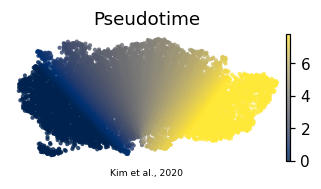

In [9]:
sub.uns['epg'] = {'NodePositions': np.asarray(sub.uns['epg']['NodePositions'])}
sub.write(os.path.join(pth_out, 'manifold.h5ad'))
xl = sub.obsm['X_umap_lin']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
plot = sub.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Kim et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
print('saved manifold.h5ad + manifold.pdf')